In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", message="Workbook contains no default style")

# FIPS → 州名映射
fips_to_state = {
    '01':'Alabama','02':'Alaska','04':'Arizona','05':'Arkansas','06':'California',
    '08':'Colorado','09':'Connecticut','10':'Delaware','11':'District of Columbia',
    '12':'Florida','13':'Georgia','15':'Hawaii','16':'Idaho','17':'Illinois',
    '18':'Indiana','19':'Iowa','20':'Kansas','21':'Kentucky','22':'Louisiana',
    '23':'Maine','24':'Maryland','25':'Massachusetts','26':'Michigan','27':'Minnesota',
    '28':'Mississippi','29':'Missouri','30':'Montana','31':'Nebraska','32':'Nevada',
    '33':'New Hampshire','34':'New Jersey','35':'New Mexico','36':'New York',
    '37':'North Carolina','38':'North Dakota','39':'Ohio','40':'Oklahoma',
    '41':'Oregon','42':'Pennsylvania','44':'Rhode Island','45':'South Carolina',
    '46':'South Dakota','47':'Tennessee','48':'Texas','49':'Utah','50':'Vermont',
    '51':'Virginia','53':'Washington','54':'West Virginia','55':'Wisconsin','56':'Wyoming'
}

# ---------- 1.1 州失业率（Excel） ----------
unemp_raw = pd.read_excel("州级年度失业率.xlsx", sheet_name="staadata",
                          skiprows=8, header=None, dtype=str)
unemp_raw = unemp_raw.iloc[:, :10]
unemp_raw.columns = ["FIPS", "State", "Year", "Population", "LaborForce_Total",
                     "LaborForce_Pct", "Employment_Total", "Employment_Pct",
                     "Unemployment_Total", "Unemployment_Rate"]

unemp_raw = unemp_raw.dropna(subset=['FIPS'])
unemp_raw = unemp_raw[unemp_raw['FIPS'].str.strip().str.len() == 2]
unemp_raw['FIPS'] = unemp_raw['FIPS'].str.strip().str.zfill(2)
unemp_raw = unemp_raw[unemp_raw['FIPS'].isin(fips_to_state)].copy()
unemp_raw['State'] = unemp_raw['FIPS'].map(fips_to_state)

unemp_raw['Year'] = pd.to_numeric(unemp_raw['Year'], errors='coerce')
unemp_raw['Unemp_Rate'] = pd.to_numeric(unemp_raw['Unemployment_Rate'], errors='coerce')
unemp = unemp_raw[['State', 'Year', 'Unemp_Rate']].dropna()
unemp['Year'] = unemp['Year'].astype(int)
unemp = unemp[(unemp['Year'] >= 2000) & (unemp['Year'] <= 2025)]
print(f"Unemployment panel: {unemp.shape}")   # 期望 (1326, 3) 左右

Unemployment panel: (1275, 3)


In [3]:
# ---------- 1.2 州级 PCE（CSV） ----------
pce_raw = pd.read_csv("Table.csv", skiprows=3)
pce_raw.columns = pce_raw.columns.str.strip()
pce_raw = pce_raw[pce_raw['GeoFIPS'].astype(str).str.match(r'^\d+$')].copy()

pce_raw['GeoFIPS'] = pce_raw['GeoFIPS'].astype(str).str.zfill(5)
pce_raw['_fips_int'] = pce_raw['GeoFIPS'].astype(int)

is_state = (pce_raw['GeoFIPS'].str.endswith('000') &
            (pce_raw['_fips_int'] > 0) &      # 排除 '00000'（United States）
            (pce_raw['_fips_int'] < 60000))    # 排除 '91000'+（New England 等地区）
pce_states = pce_raw[is_state].rename(columns={'GeoName': 'State'}).copy()

year_cols = [str(y) for y in range(1997, 2026)]
pce_long = pce_states.melt(id_vars=['GeoFIPS', 'State'],
                           value_vars=year_cols,
                           var_name='Year', value_name='PCE_Millions')
pce_long['Year'] = pce_long['Year'].astype(int)
pce_long['PCE_Millions'] = pd.to_numeric(pce_long['PCE_Millions'], errors='coerce')
pce_long = pce_long.dropna(subset=['PCE_Millions'])
pce_long = pce_long[(pce_long['Year'] >= 2000) & (pce_long['Year'] <= 2025)]
print(f"PCE panel: {pce_long.shape}") 

PCE panel: (1326, 4)


In [5]:
# ---------- 1.3 合并成 state-year 面板 ----------
panel = unemp.merge(pce_long[['State', 'Year', 'PCE_Millions']],
                    on=['State', 'Year'], how='inner')
print(f"Merged panel: {panel.shape}")

#
panel = panel.sort_values(['State', 'Year'])
panel['PCE_Growth'] = panel.groupby('State')['PCE_Millions'].pct_change() * 100
panel['Unemp_Change'] = panel.groupby('State')['Unemp_Rate'].diff()

panel.to_csv("state_unemp_pce_panel.csv", index=False)

Merged panel: (1275, 4)


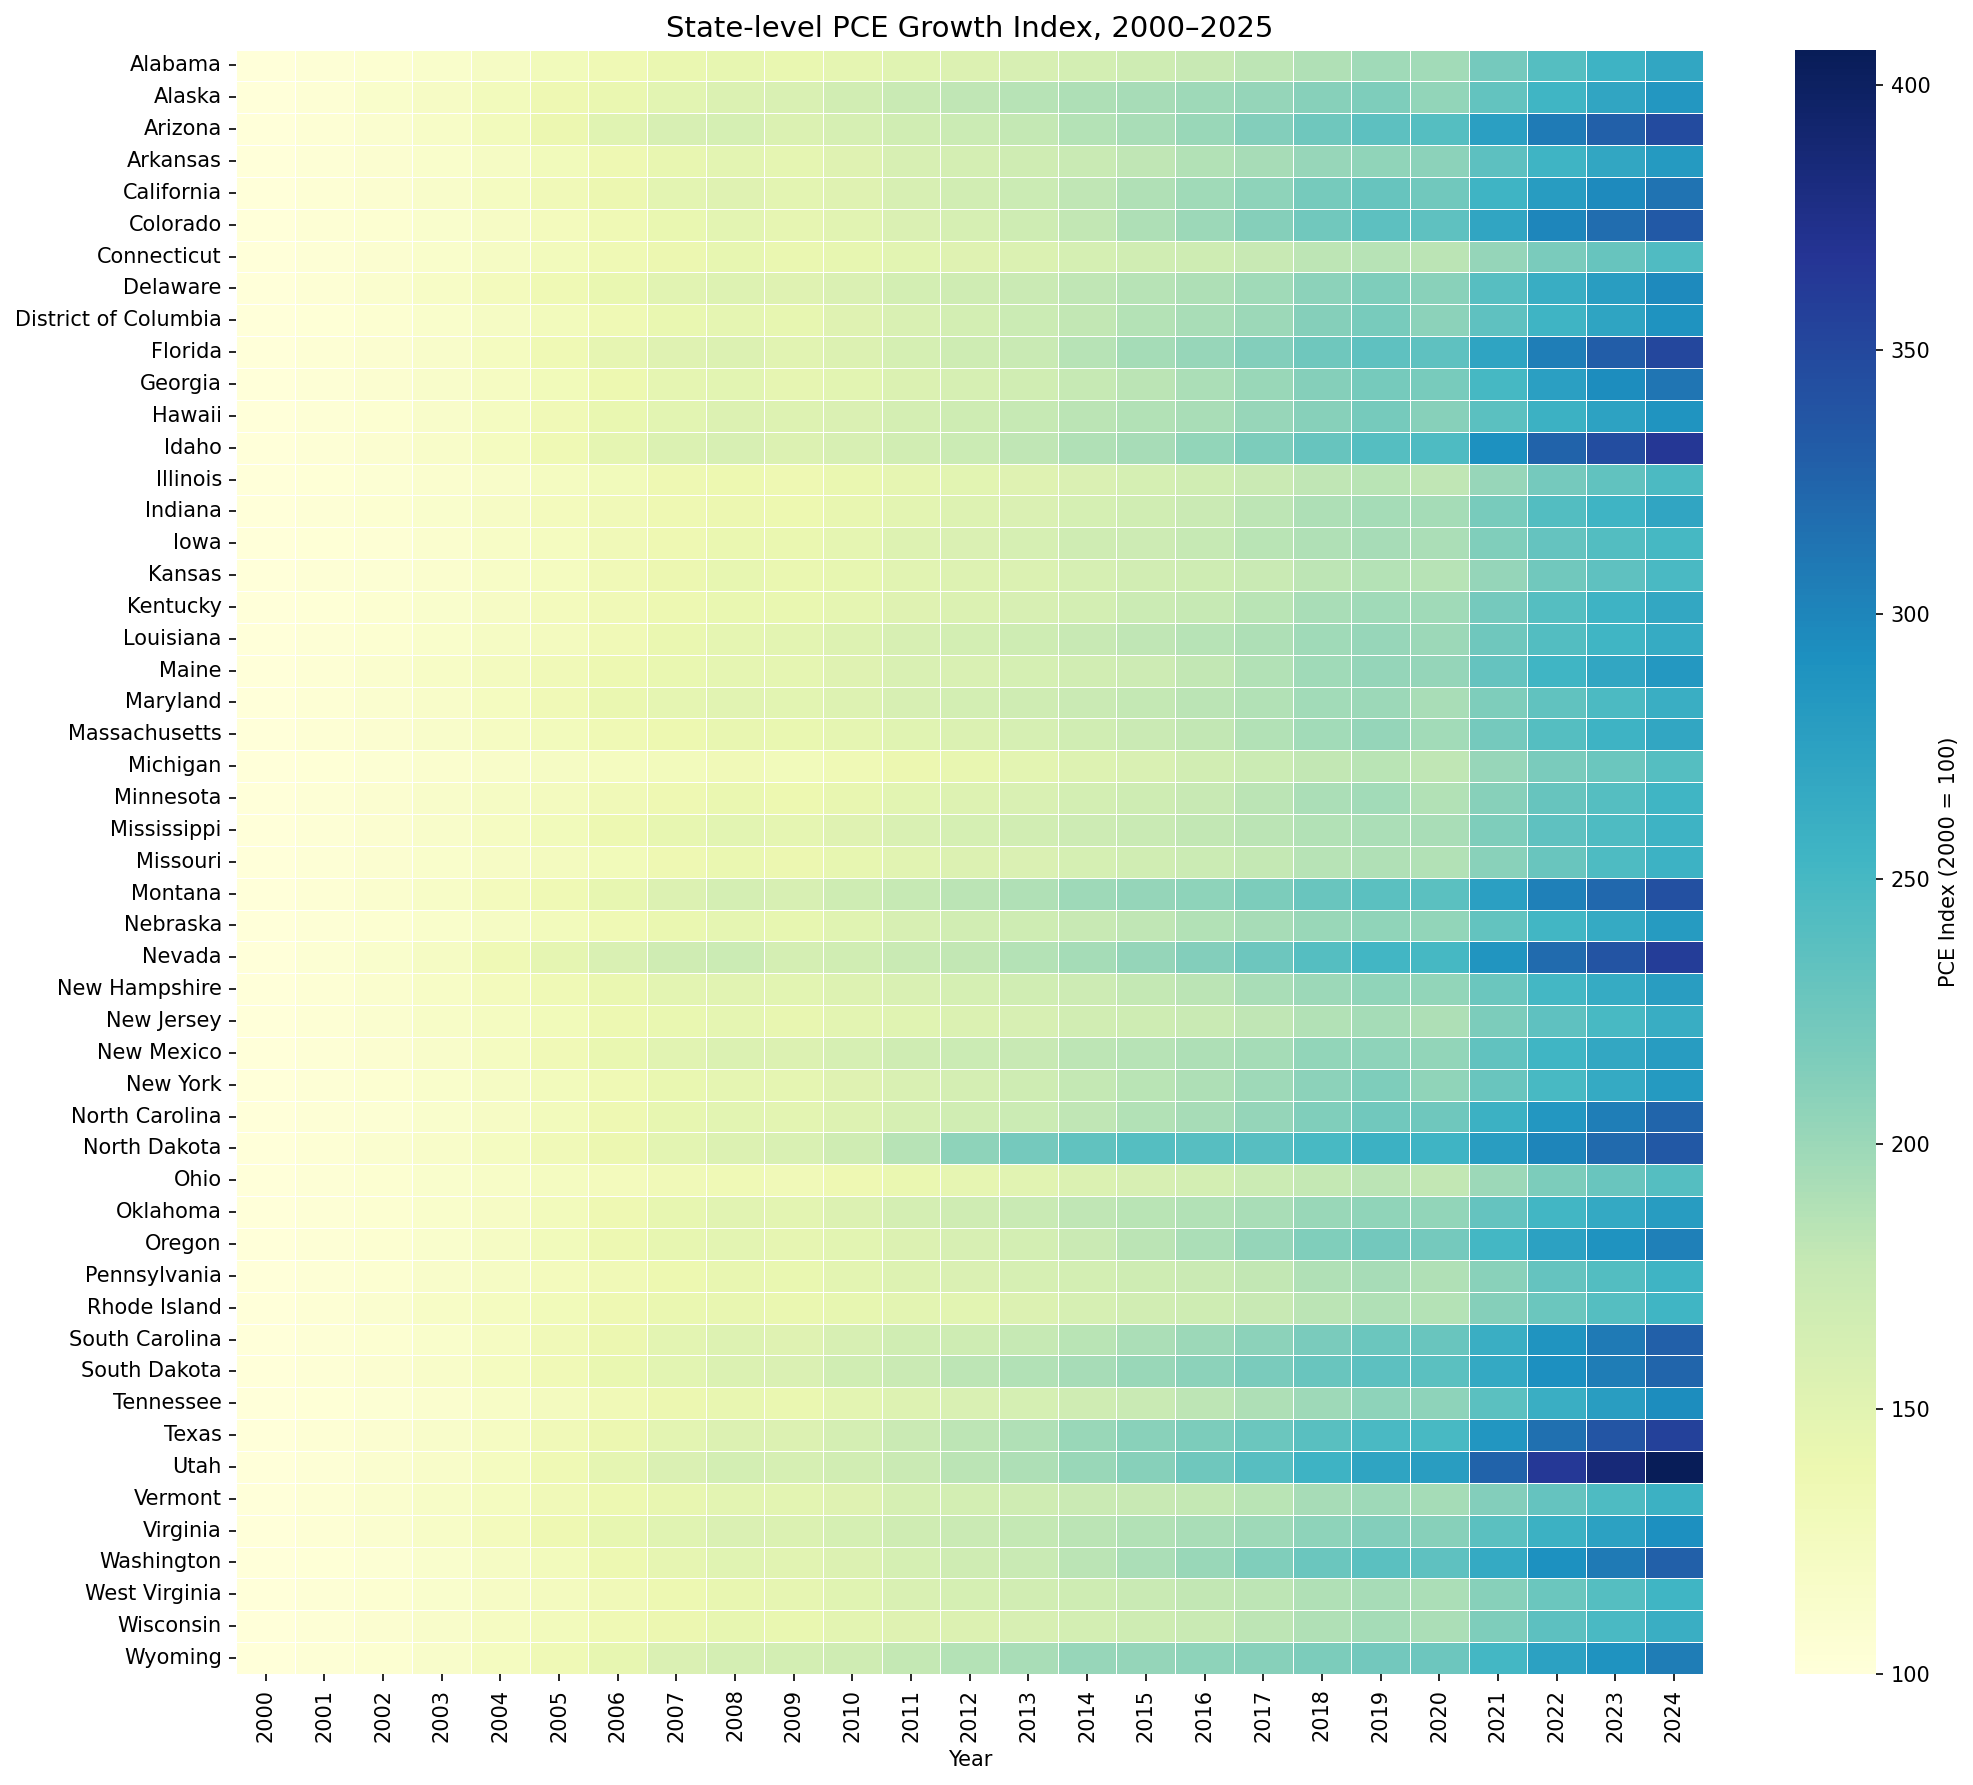

In [12]:
pce_idx = panel.copy()
base = pce_idx[pce_idx['Year'] == 2000].set_index('State')['PCE_Millions']
pce_idx['PCE_Index'] = pce_idx.apply(
    lambda r: r['PCE_Millions'] / base[r['State']] * 100, axis=1)
state_year_idx = pce_idx.pivot(index='State', columns='Year', values='PCE_Index')

plt.figure(figsize=(14, 12), dpi=150)
sns.heatmap(state_year_idx, cmap='YlGnBu',
            linewidths=0.3, linecolor='white',
            cbar_kws={'label': 'PCE Index (2000 = 100)'})
plt.title('State-level PCE Growth Index, 2000–2025', fontsize=14)
plt.xlabel('Year'); plt.ylabel('')
plt.tight_layout(); plt.show()


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_43316\3250444685.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g['Unemp_Rate'].corr(g['PCE_Growth']))
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_43316\3250444685.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=corr_by_state, y='State', x='Corr',


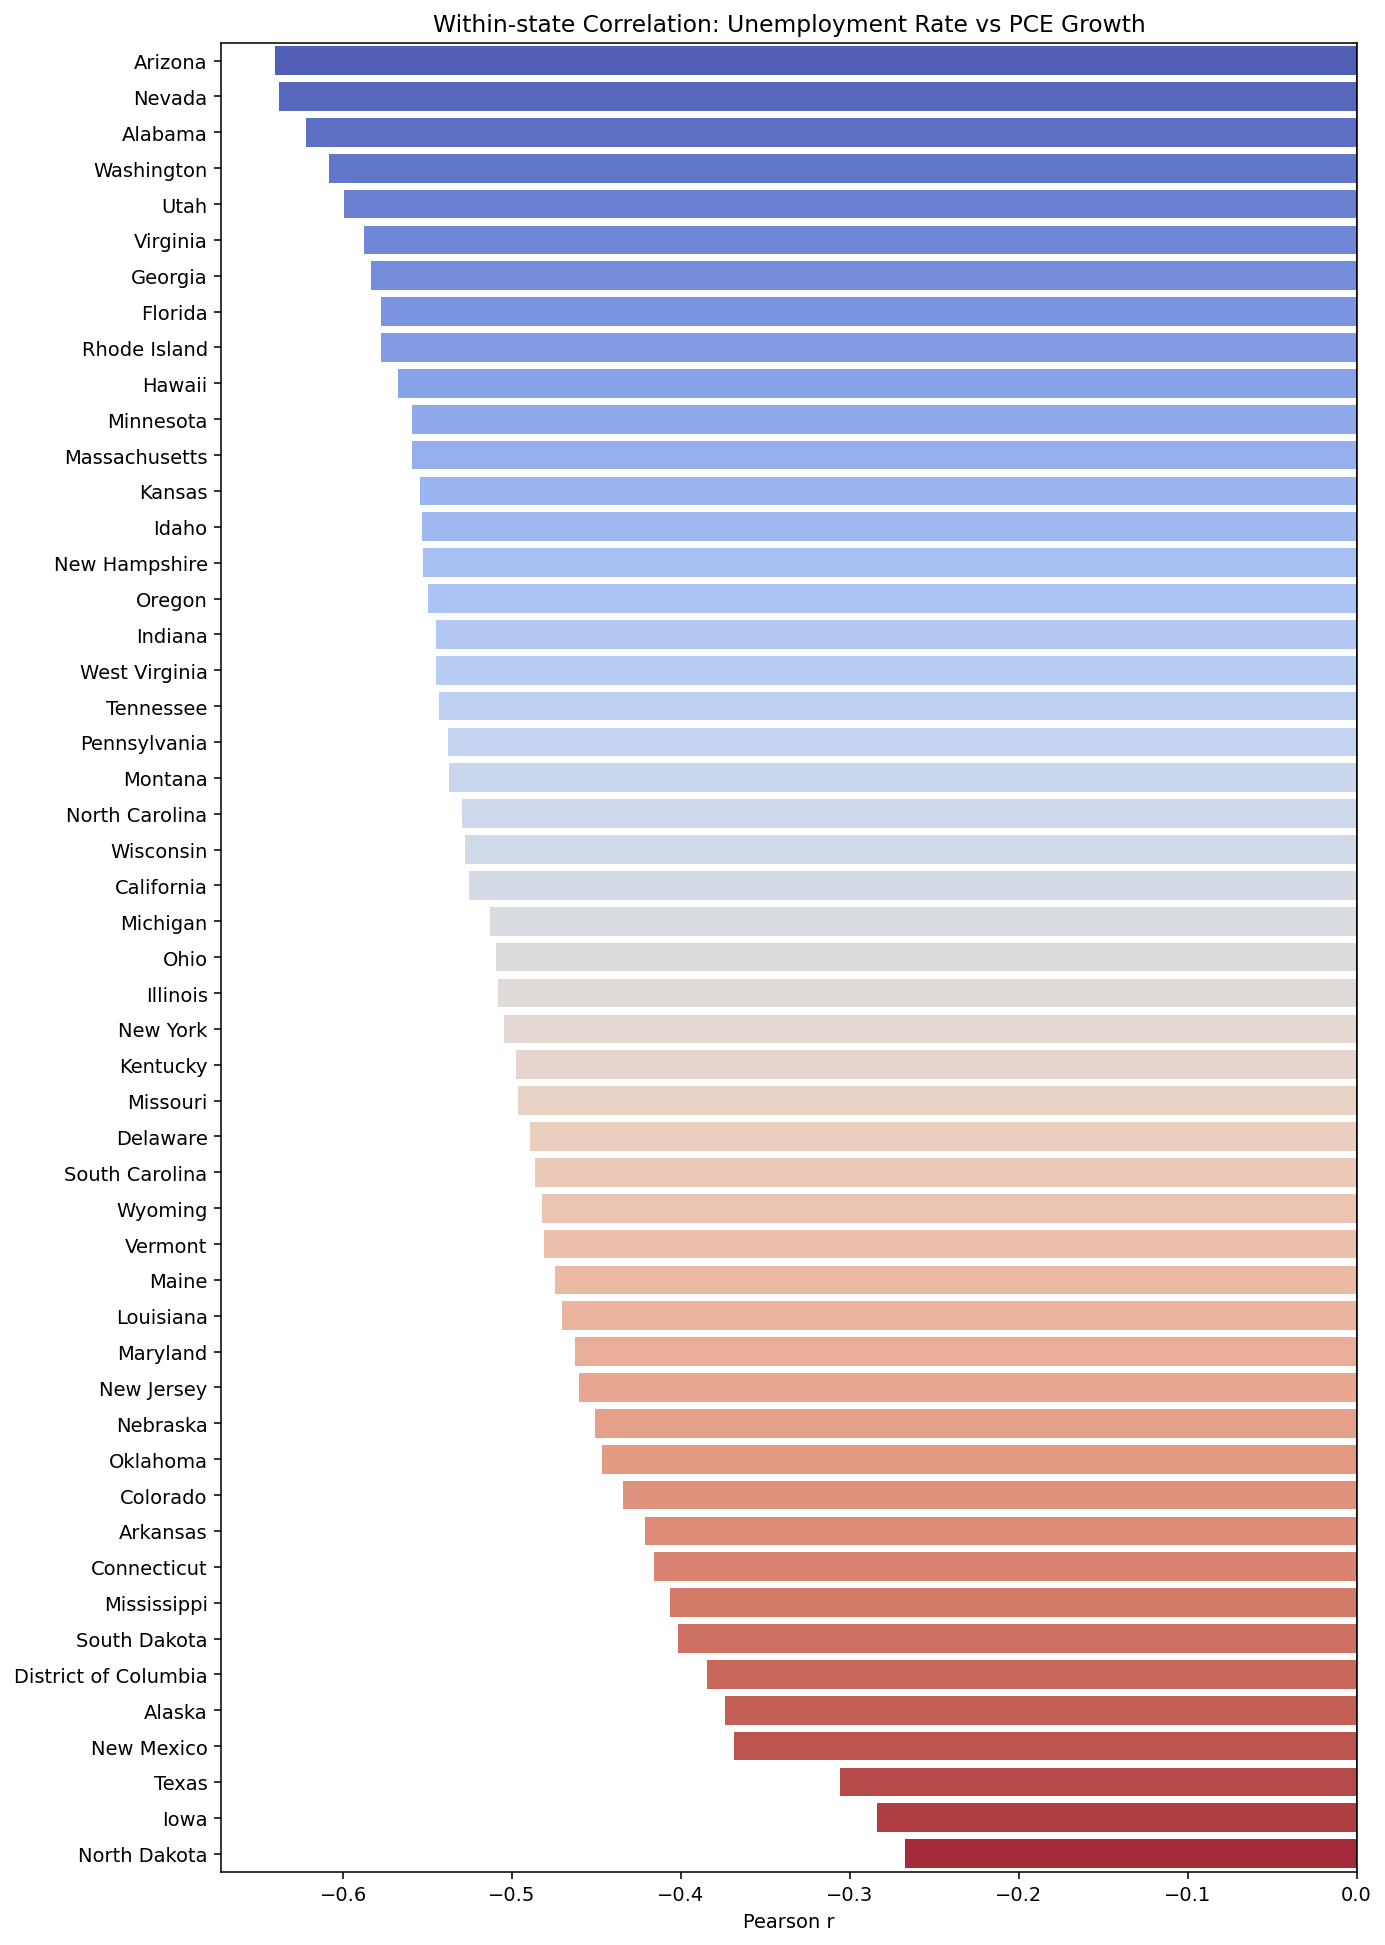

In [17]:
# 每个州内：失业率 vs PCE 增长率 的相关性（同一年）
corr_by_state = (panel.dropna(subset=['PCE_Growth'])
                      .groupby('State')
                      .apply(lambda g: g['Unemp_Rate'].corr(g['PCE_Growth']))
                      .reset_index(name='Corr'))
corr_by_state = corr_by_state.sort_values('Corr')

plt.figure(figsize=(10, 14), dpi=140)
sns.barplot(data=corr_by_state, y='State', x='Corr',
            palette='coolwarm', orient='h')
plt.axvline(0, color='k', lw=0.8)
plt.title('Within-state Correlation: Unemployment Rate vs PCE Growth')
plt.xlabel('Pearson r'); plt.ylabel('')
plt.tight_layout(); plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_43316\103894086.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g['Unemp_Rate'].corr(g['PCE_Growth']))


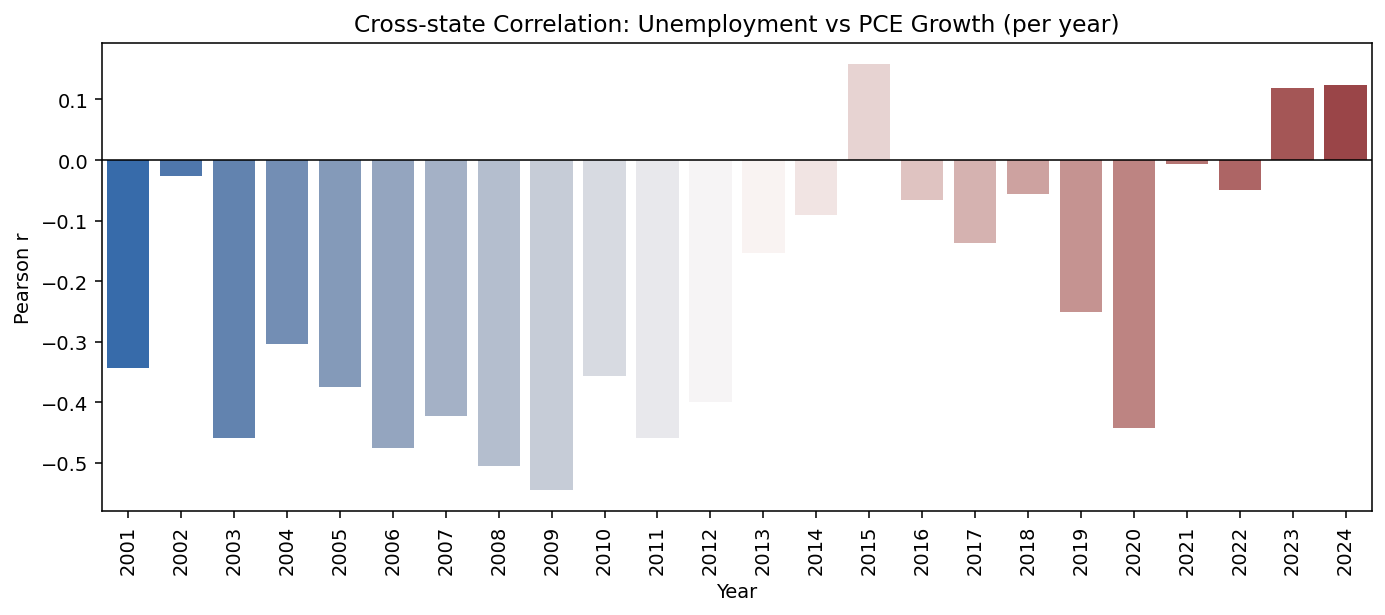

In [19]:
###	固定年，跨州  "同一年里，失业率高的州，消费增长是否更低？"

year_corr = (panel.dropna(subset=['PCE_Growth'])
                   .groupby('Year')
                   .apply(lambda g: g['Unemp_Rate'].corr(g['PCE_Growth']))
                   .reset_index(name='Cross_State_Corr'))

plt.figure(figsize=(10, 4.5), dpi=140)
sns.barplot(data=year_corr, x='Year', y='Cross_State_Corr',
            hue='Year', palette='vlag', legend=False)
plt.axhline(0, color='k', lw=0.8)
plt.title('Cross-state Correlation: Unemployment vs PCE Growth (per year)')
plt.xlabel('Year'); plt.ylabel('Pearson r')
plt.xticks(rotation=90)
plt.tight_layout(); plt.show()